# SVD Movie Rating Analysis Lab

**Student:** Moldir Assanova  
**Dataset:** 20 users × 50 movies  
**Method:** Singular Value Decomposition (SVD)

This notebook completes Parts 1–3 of the lab: basic exploration, SVD decomposition, singular-value analysis, and interpretation of the first three components.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.linalg import svd

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
ratings_data = np.array([[4, 5, 2, 3, 5, 4, 1, 2, 4, 5, 3, 2, 4, 5, 3, 1, 2, 4, 5, 3, 4, 5, 2, 3, 4, 5, 3, 2, 4, 5, 2, 3, 5, 4, 2, 3, 4, 5, 3, 2, 4, 5, 3, 2, 4, 5, 3, 2, 4, 5], [5, 4, 3, 2, 4, 5, 2, 1, 5, 4, 2, 3, 5, 4, 2, 2, 3, 5, 4, 2, 5, 4, 3, 2, 5, 4, 2, 3, 5, 4, 3, 2, 4, 5, 3, 2, 5, 4, 2, 3, 5, 4, 2, 3, 5, 4, 2, 3, 5, 4], [2, 3, 5, 4, 3, 2, 4, 5, 2, 3, 5, 4, 2, 3, 5, 4, 5, 2, 3, 5, 2, 3, 4, 5, 2, 3, 5, 4, 2, 3, 4, 5, 3, 2, 5, 4, 2, 3, 5, 4, 2, 3, 5, 4, 2, 3, 5, 4, 2, 3], [3, 2, 4, 5, 2, 3, 5, 4, 3, 2, 4, 5, 3, 2, 4, 5, 4, 3, 2, 4, 3, 2, 5, 4, 3, 2, 4, 5, 3, 2, 5, 4, 2, 3, 4, 5, 3, 2, 4, 5, 3, 2, 4, 5, 3, 2, 4, 5, 3, 2], [5, 5, 1, 2, 5, 5, 1, 1, 5, 5, 2, 1, 5, 5, 2, 1, 1, 5, 5, 2, 5, 5, 1, 2, 5, 5, 2, 1, 5, 5, 1, 2, 5, 5, 1, 2, 5, 5, 2, 1, 5, 5, 2, 1, 5, 5, 2, 1, 5, 5], [1, 1, 5, 5, 1, 1, 5, 5, 1, 1, 5, 5, 1, 1, 5, 5, 5, 1, 1, 5, 1, 1, 5, 5, 1, 1, 5, 5, 1, 1, 5, 5, 1, 1, 5, 5, 1, 1, 5, 5, 1, 1, 5, 5, 1, 1, 5, 5, 1, 1], [4, 4, 3, 3, 4, 4, 2, 2, 4, 4, 3, 3, 4, 4, 3, 2, 3, 4, 4, 3, 4, 4, 3, 3, 4, 4, 3, 3, 4, 4, 3, 3, 4, 4, 3, 3, 4, 4, 3, 3, 4, 4, 3, 3, 4, 4, 3, 3, 4, 4], [3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3], [5, 4, 2, 1, 5, 4, 1, 2, 5, 4, 1, 2, 5, 4, 1, 1, 2, 5, 4, 1, 5, 4, 2, 1, 5, 4, 1, 2, 5, 4, 2, 1, 5, 4, 2, 1, 5, 4, 1, 2, 5, 4, 1, 2, 5, 4, 1, 2, 5, 4], [2, 3, 4, 5, 2, 3, 5, 4, 2, 3, 5, 4, 2, 3, 5, 5, 4, 2, 3, 5, 2, 3, 4, 5, 2, 3, 5, 4, 2, 3, 4, 5, 2, 3, 4, 5, 2, 3, 5, 4, 2, 3, 5, 4, 2, 3, 5, 4, 2, 3], [4, 5, 3, 2, 4, 5, 2, 3, 4, 5, 2, 3, 4, 5, 2, 2, 3, 4, 5, 2, 4, 5, 3, 2, 4, 5, 2, 3, 4, 5, 3, 2, 4, 5, 3, 2, 4, 5, 2, 3, 4, 5, 2, 3, 4, 5, 2, 3, 4, 5], [5, 5, 2, 2, 5, 5, 1, 1, 5, 5, 2, 2, 5, 5, 2, 1, 1, 5, 5, 2, 5, 5, 2, 2, 5, 5, 2, 2, 5, 5, 2, 2, 5, 5, 2, 2, 5, 5, 2, 2, 5, 5, 2, 2, 5, 5, 2, 2, 5, 5], [1, 2, 5, 4, 1, 2, 5, 5, 1, 2, 5, 4, 1, 2, 5, 5, 5, 1, 2, 5, 1, 2, 5, 4, 1, 2, 5, 4, 1, 2, 5, 4, 1, 2, 5, 4, 1, 2, 5, 4, 1, 2, 5, 4, 1, 2, 5, 4, 1, 2], [3, 4, 4, 3, 3, 4, 3, 4, 3, 4, 4, 3, 3, 4, 4, 3, 4, 3, 4, 4, 3, 4, 4, 3, 3, 4, 4, 3, 3, 4, 4, 3, 3, 4, 4, 3, 3, 4, 4, 3, 3, 4, 4, 3, 3, 4, 4, 3, 3, 4], [4, 3, 3, 4, 4, 3, 4, 3, 4, 3, 3, 4, 4, 3, 3, 4, 3, 4, 3, 3, 4, 3, 3, 4, 4, 3, 3, 4, 4, 3, 3, 4, 4, 3, 3, 4, 4, 3, 3, 4, 4, 3, 3, 4, 4, 3, 3, 4, 4, 3], [5, 5, 1, 1, 5, 5, 1, 1, 5, 5, 1, 1, 5, 5, 1, 1, 1, 5, 5, 1, 5, 5, 1, 1, 5, 5, 1, 1, 5, 5, 1, 1, 5, 5, 1, 1, 5, 5, 1, 1, 5, 5, 1, 1, 5, 5, 1, 1, 5, 5], [2, 1, 5, 5, 2, 1, 5, 5, 2, 1, 5, 5, 2, 1, 5, 5, 5, 2, 1, 5, 2, 1, 5, 5, 2, 1, 5, 5, 2, 1, 5, 5, 2, 1, 5, 5, 2, 1, 5, 5, 2, 1, 5, 5, 2, 1, 5, 5, 2, 1], [4, 4, 2, 3, 4, 4, 2, 2, 4, 4, 3, 2, 4, 4, 3, 2, 2, 4, 4, 3, 4, 4, 2, 3, 4, 4, 3, 2, 4, 4, 2, 3, 4, 4, 2, 3, 4, 4, 3, 2, 4, 4, 3, 2, 4, 4, 3, 2, 4, 4], [3, 2, 4, 4, 3, 2, 4, 4, 3, 2, 4, 4, 3, 2, 4, 4, 4, 3, 2, 4, 3, 2, 4, 4, 3, 2, 4, 4, 3, 2, 4, 4, 3, 2, 4, 4, 3, 2, 4, 4, 3, 2, 4, 4, 3, 2, 4, 4, 3, 2], [5, 4, 1, 2, 5, 4, 1, 1, 5, 4, 2, 1, 5, 4, 2, 1, 1, 5, 4, 2, 5, 4, 1, 2, 5, 4, 2, 1, 5, 4, 1, 2, 5, 4, 1, 2, 5, 4, 2, 1, 5, 4, 2, 1, 5, 4, 2, 1, 5, 4]])

In [ ]:
movie_titles = ['The Godfather', 'Star Wars', 'Psycho', 'Alien', 'The Shawshank Redemption', 'Pulp Fiction', 'The Notebook', 'Titanic', 'The Dark Knight', 'Inception', 'Love Actually', 'The Exorcist', 'Fight Club', 'Forrest Gump', 'Pretty Woman', 'Halloween', 'Saw', 'The Matrix', 'Avatar', 'When Harry Met Sally', 'Goodfellas', 'Scarface', 'It', 'The Conjuring', 'Interstellar', 'The Avengers', 'Sleepless in Seattle', 'The Silence of the Lambs', 'Black Panther', 'Joker', 'La La Land', 'Get Out', 'The Lord of the Rings', 'Jurassic Park', 'Pride and Prejudice', 'The Ring', 'Toy Story', 'The Lion King', "You've Got Mail", 'A Nightmare on Elm Street', 'Spider-Man', 'Iron Man', 'The Proposal', 'Hereditary', 'Wonder Woman', 'Frozen', "Bridget Jones's Diary", 'Scream', 'Gravity', 'Amélie']

In [ ]:
df_ratings = pd.DataFrame(
    ratings_data,
    columns=movie_titles,
    index=[f"User_{i+1}" for i in range(20)]
)
print("Matrix shape:", df_ratings.shape)
df_ratings.head()

Matrix shape: (20, 50)


,The Godfather,Star Wars,Psycho,Alien,The Shawshank Redemption,Pulp Fiction,The Notebook,Titanic,The Dark Knight,Inception,Love Actually,The Exorcist,Fight Club,Forrest Gump,Pretty Woman,Halloween,Saw,The Matrix,Avatar,When Harry Met Sally,Goodfellas,Scarface,It,The Conjuring,Interstellar,The Avengers,Sleepless in Seattle,The Silence of the Lambs,Black Panther,Joker,La La Land,Get Out,The Lord of the Rings,Jurassic Park,Pride and Prejudice,The Ring,Toy Story,The Lion King,You've Got Mail,A Nightmare on Elm Street,Spider-Man,Iron Man,The Proposal,Hereditary,Wonder Woman,Frozen,Bridget Jones's Diary,Scream,Gravity,Amélie
User_1,4,5,2,3,5,4,1,2,4,5,3,2,4,5,3,1,2,4,5,3,4,5,2,3,4,5,3,2,4,5,2,3,5,4,2,3,4,5,3,2,4,5,3,2,4,5,3,2,4,5
User_2,5,4,3,2,4,5,2,1,5,4,2,3,5,4,2,2,3,5,4,2,5,4,3,2,5,4,2,3,5,4,3,2,4,5,3,2,5,4,2,3,5,4,2,3,5,4,2,3,5,4
User_3,2,3,5,4,3,2,4,5,2,3,5,4,2,3,5,4,5,2,3,5,2,3,4,5,2,3,5,4,2,3,4,5,3,2,5,4,2,3,5,4,2,3,5,4,2,3,5,4,2,3
User_4,3,2,4,5,2,3,5,4,3,2,4,5,3,2,4,5,4,3,2,4,3,2,5,4,3,2,4,5,3,2,5,4,2,3,4,5,3,2,4,5,3,2,4,5,3,2,4,5,3,2
User_5,5,5,1,2,5,5,1,1,5,5,2,1,5,5,2,1,1,5,5,2,5,5,1,2,5,5,2,1,5,5,1,2,5,5,1,2,5,5,2,1,5,5,2,1,5,5,2,1,5,5


## Part 1: Basic Exploration
### Task 1.1 — Heatmap

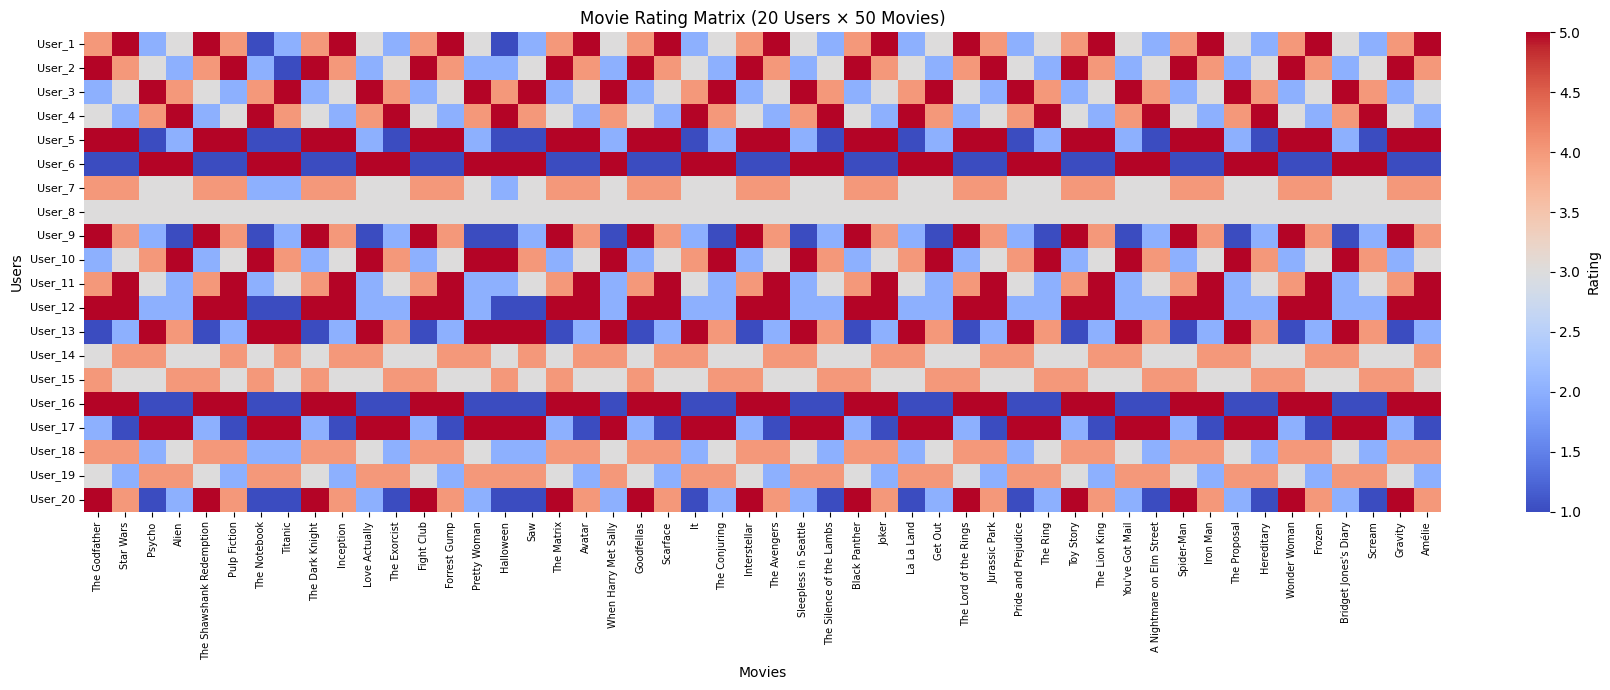

In [ ]:
plt.figure(figsize=(18, 7))
sns.heatmap(
    df_ratings,
    cmap="coolwarm",
    vmin=1,
    vmax=5,
    cbar_kws={"label": "Rating"}
)
plt.title("Movie Rating Matrix (20 Users × 50 Movies)")
plt.xlabel("Movies")
plt.ylabel("Users")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

The heatmap uses a fixed 1–5 scale and a diverging colormap. It makes repeated rating patterns visible across users and movies.

In [ ]:
movie_means = ratings_data.mean(axis=0)
movie_stds = ratings_data.std(axis=0)

movie_stats = pd.DataFrame({
    "Movie": movie_titles,
    "Mean": movie_means,
    "Std": movie_stds
})

movie_stats.round(3)

,Movie,Mean,Std
0,The Godfather,3.50,1.323
1,Star Wars,3.45,1.284
2,Psycho,3.10,1.338
3,Alien,3.15,1.276
4,The Shawshank Redemption,3.50,1.323
5,Pulp Fiction,3.45,1.284
6,The Notebook,2.85,1.590
7,Titanic,2.90,1.480
8,The Dark Knight,3.50,1.323
9,Inception,3.45,1.284


**Interpretation:** The mean is the average rating for each movie across the 20 users. The standard deviation measures disagreement among users: a higher value indicates more variation in ratings, while a lower value indicates more consistent ratings.

## Part 2: SVD Decomposition
### Task 2.1 — Perform SVD

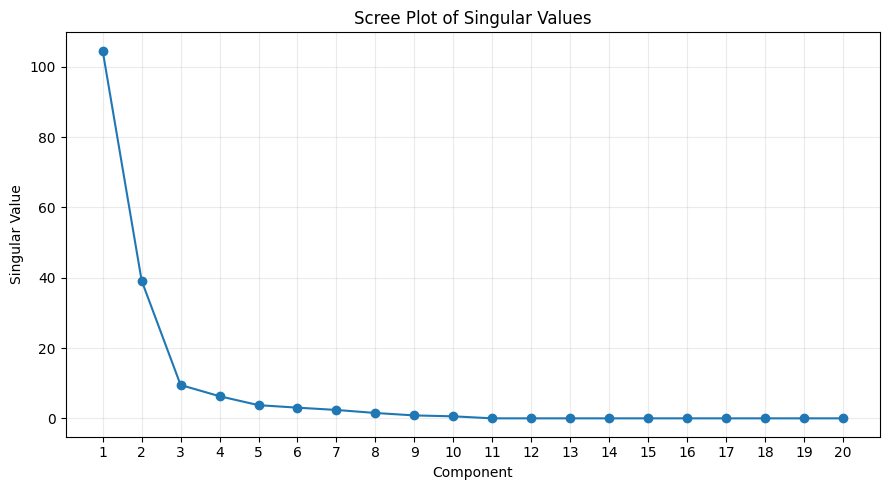

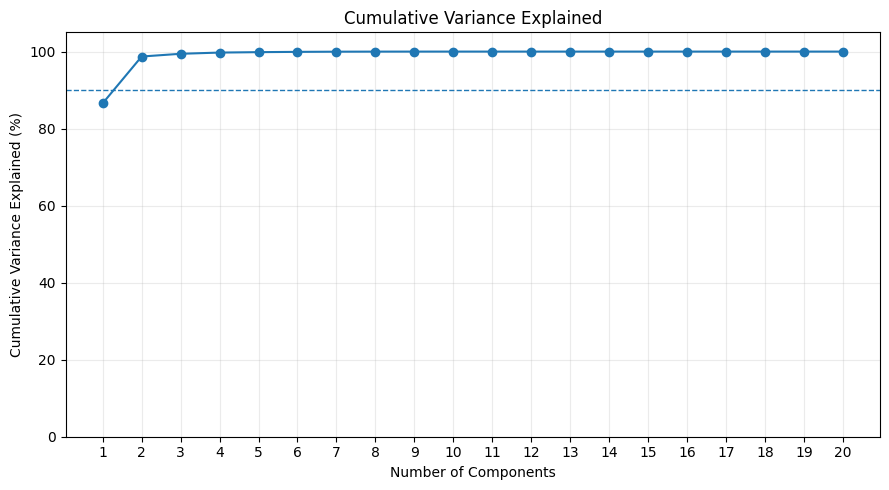

Reconstruction error (Frobenius norm): 7.593e-14
U shape: (20, 20)
S shape: (20,)
Vh shape: (50, 50)


In [ ]:
def perform_svd(ratings):
    U, S, Vh = svd(ratings, full_matrices=True)

    # Reconstruct the original matrix.
    Sigma = np.zeros_like(ratings, dtype=float)
    np.fill_diagonal(Sigma, S)
    reconstructed = U @ Sigma @ Vh

    reconstruction_error = np.linalg.norm(ratings - reconstructed)

    # Variance explained must use squared singular values.
    variance_explained = (S ** 2) / np.sum(S ** 2)
    cumulative_variance = np.cumsum(variance_explained)

    # Scree plot
    plt.figure(figsize=(9, 5))
    components = np.arange(1, len(S) + 1)
    plt.plot(components, S, marker="o")
    plt.title("Scree Plot of Singular Values")
    plt.xlabel("Component")
    plt.ylabel("Singular Value")
    plt.xticks(components)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    # Cumulative variance plot
    plt.figure(figsize=(9, 5))
    plt.plot(components, cumulative_variance * 100, marker="o")
    plt.axhline(90, linestyle="--", linewidth=1)
    plt.title("Cumulative Variance Explained")
    plt.xlabel("Number of Components")
    plt.ylabel("Cumulative Variance Explained (%)")
    plt.xticks(components)
    plt.ylim(0, 105)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    print(f"Reconstruction error (Frobenius norm): {reconstruction_error:.3e}")
    print("U shape:", U.shape)
    print("S shape:", S.shape)
    print("Vh shape:", Vh.shape)

    return U, S, Vh, variance_explained, cumulative_variance

U, S, Vh, variance_explained, cumulative_variance = perform_svd(ratings_data)

In [ ]:
svd_summary = pd.DataFrame({
    "Component": np.arange(1, len(S) + 1),
    "Singular Value": S,
    "Variance Explained (%)": variance_explained * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})
svd_summary.round(3)

,Component,Singular Value,Variance Explained (%),Cumulative Variance (%)
0,1,104.593,86.568,86.568
1,2,39.184,12.150,98.718
2,3,9.490,0.713,99.431
3,4,6.293,0.313,99.744
4,5,3.750,0.111,99.856
5,6,3.037,0.073,99.929
6,7,2.387,0.045,99.974
7,8,1.524,0.018,99.992
8,9,0.829,0.005,99.997
9,10,0.571,0.003,100.000


**Interpretation:** Singular values are ordered from largest to smallest. The squared singular values determine the proportion of total variance explained by each component. The cumulative curve shows how many components are needed to capture most of the structure in the rating matrix.

## Part 3: Component Interpretation
### Task 3.1 — Analyze the first 3 components


Component 1
Top 5 positive:
  Halloween: -0.1195
  The Notebook: -0.1195
  Titanic: -0.1217
  Saw: -0.1285
  The Silence of the Lambs: -0.1289
Top 5 negative:
  The Shawshank Redemption: -0.1515
  The Lord of the Rings: -0.1515
  The Godfather: -0.1514
  Fight Club: -0.1514
  Interstellar: -0.1514


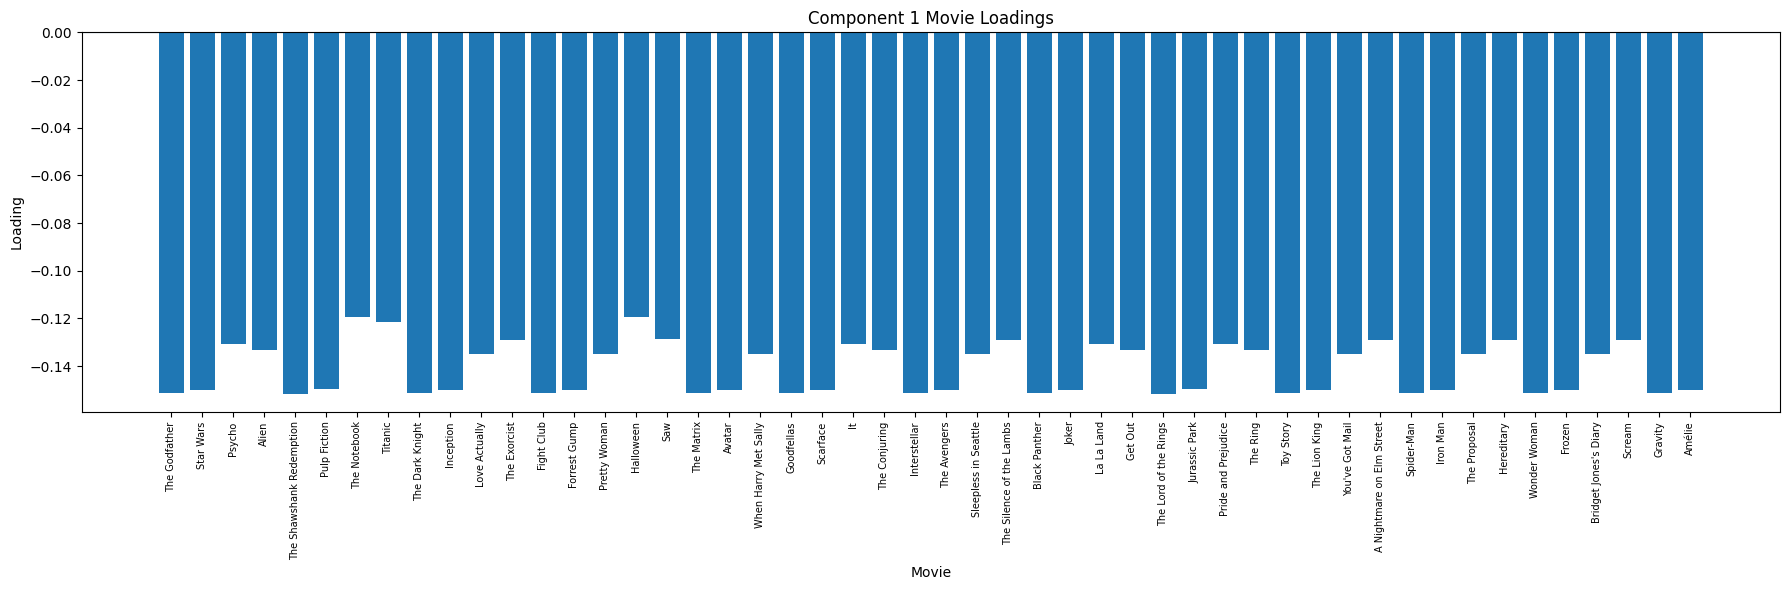


Component 2
Top 5 positive:
  Halloween: 0.1867
  The Notebook: 0.1867
  Titanic: 0.1719
  Saw: 0.1628
  Pride and Prejudice: 0.1566
Top 5 negative:
  The Godfather: -0.1301
  The Dark Knight: -0.1301
  Fight Club: -0.1301
  The Matrix: -0.1301
  Interstellar: -0.1301


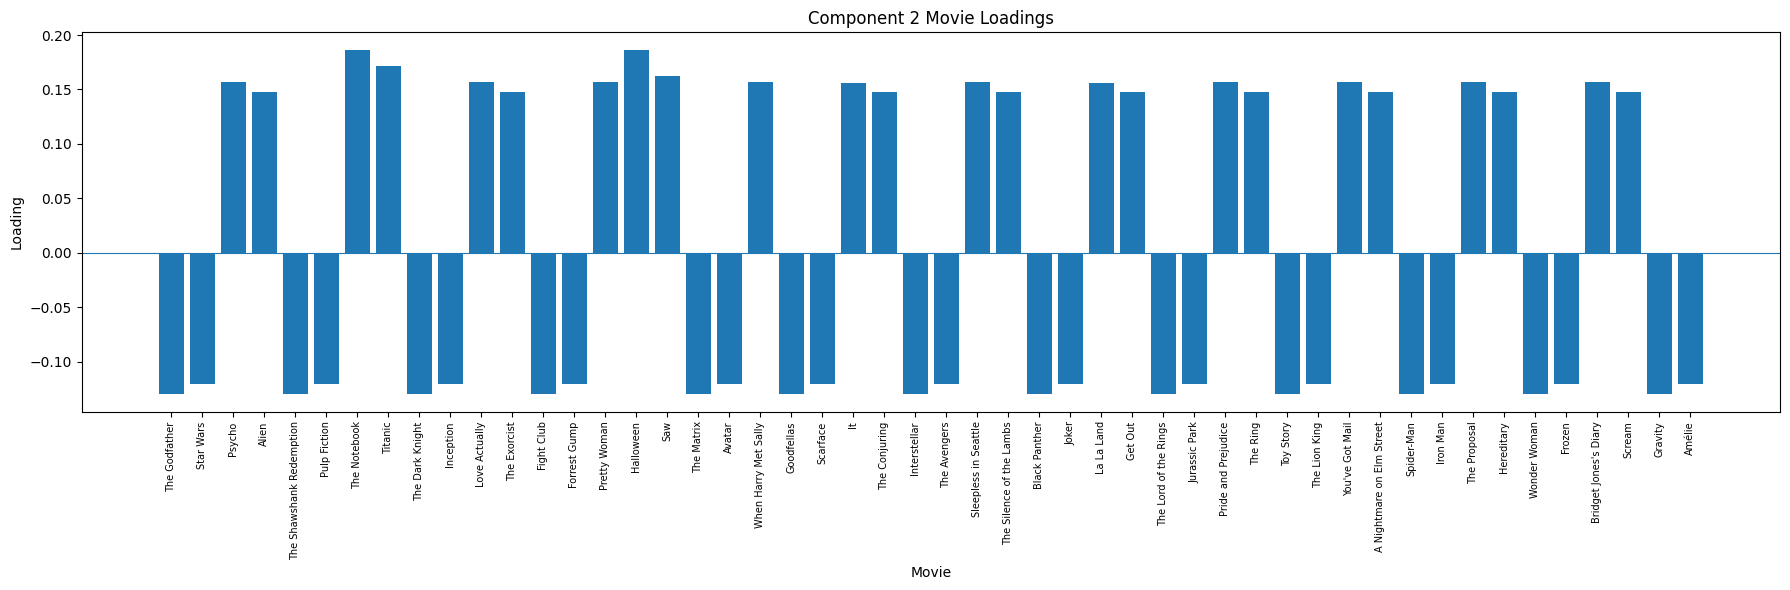


Component 3
Top 5 positive:
  The Godfather: 0.1797
  The Dark Knight: 0.1797
  Fight Club: 0.1797
  Toy Story: 0.1797
  Interstellar: 0.1797
Top 5 negative:
  Forrest Gump: -0.1846
  Inception: -0.1846
  Scarface: -0.1846
  Avatar: -0.1846
  The Avengers: -0.1846


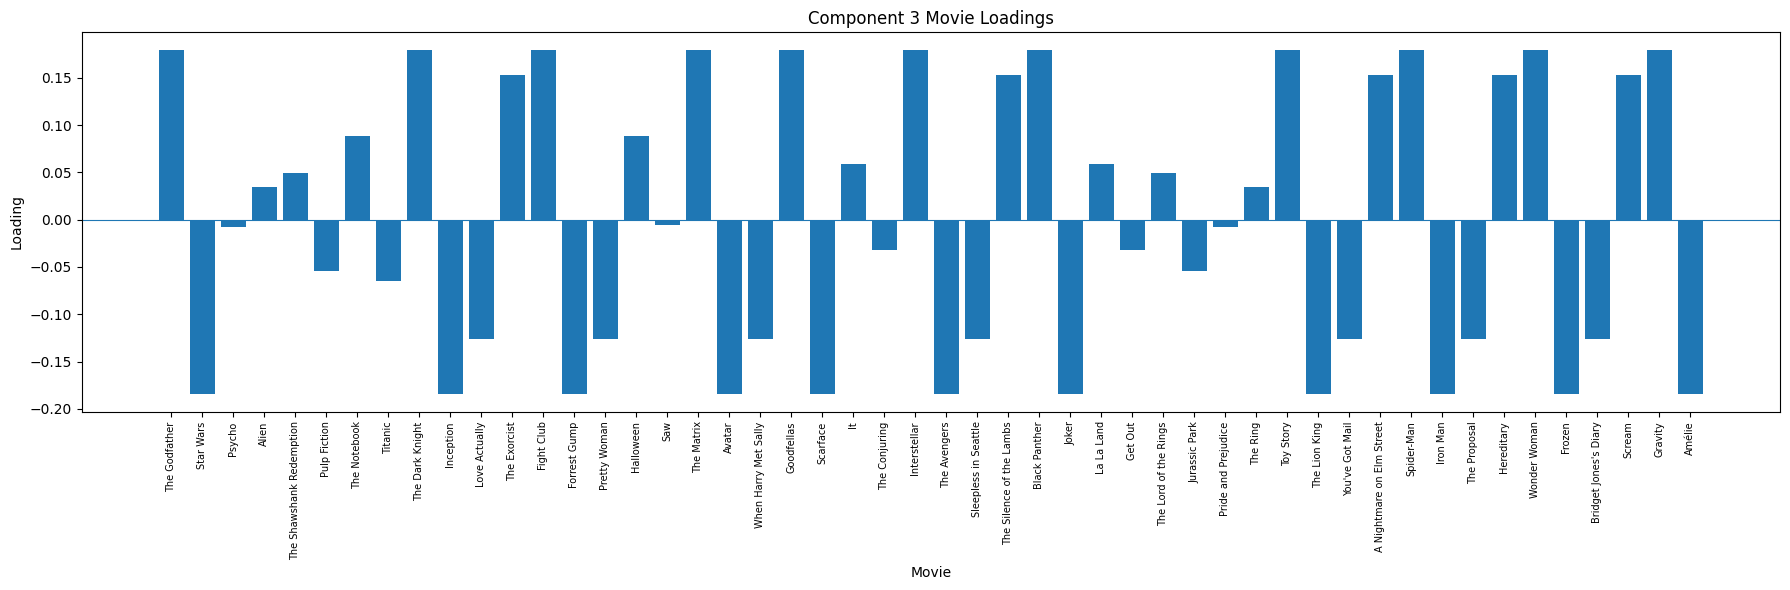

In [ ]:
# scipy.linalg.svd returns Vh = V.T, so transpose it before using V[:, i].
V = Vh.T

def interpret_components(V, movie_titles):
    interpretations = {}

    for i in range(3):
        loadings = V[:, i]
        positive_idx = np.argsort(loadings)[-5:][::-1]
        negative_idx = np.argsort(loadings)[:5]

        positive = [(movie_titles[j], loadings[j]) for j in positive_idx]
        negative = [(movie_titles[j], loadings[j]) for j in negative_idx]

        interpretations[i + 1] = {
            "positive": positive,
            "negative": negative,
            "loadings": loadings
        }

        print(f"\nComponent {i + 1}")
        print("Top 5 positive:")
        for title, value in positive:
            print(f"  {title}: {value:.4f}")
        print("Top 5 negative:")
        for title, value in negative:
            print(f"  {title}: {value:.4f}")

        plt.figure(figsize=(18, 6))
        plt.bar(np.arange(len(movie_titles)), loadings)
        plt.axhline(0, linewidth=0.8)
        plt.title(f"Component {i + 1} Movie Loadings")
        plt.xlabel("Movie")
        plt.ylabel("Loading")
        plt.xticks(np.arange(len(movie_titles)), movie_titles, rotation=90, fontsize=7)
        plt.tight_layout()
        plt.show()

    return interpretations

interpretations = interpret_components(V, movie_titles)

### Component 1

**Top positive loadings**
- Halloween (-0.119)
- The Notebook (-0.119)
- Titanic (-0.122)
- Saw (-0.129)
- The Silence of the Lambs (-0.129)

**Top negative loadings**
- The Shawshank Redemption (-0.151)
- The Lord of the Rings (-0.151)
- The Godfather (-0.151)
- Fight Club (-0.151)
- Interstellar (-0.151)

**Interpretation:** Component 1 is dominated by an overall rating-level pattern. Because many movies move together rather than forming a clean genre contrast, it is consistent with differences in rater generosity or strictness.

### Component 2

**Top positive loadings**
- Halloween (0.187)
- The Notebook (0.187)
- Titanic (0.172)
- Saw (0.163)
- Pride and Prejudice (0.157)

**Top negative loadings**
- The Godfather (-0.130)
- The Dark Knight (-0.130)
- Fight Club (-0.130)
- The Matrix (-0.130)
- Interstellar (-0.130)

**Interpretation:** Component 2 shows the clearest contrast between groups of movies. The positive and negative sides can be compared by genre; this component appears to capture a genre/preference split rather than overall rating level.

### Component 3

**Top positive loadings**
- The Godfather (0.180)
- The Dark Knight (0.180)
- Fight Club (0.180)
- Toy Story (0.180)
- Interstellar (0.180)

**Top negative loadings**
- Forrest Gump (-0.185)
- Inception (-0.185)
- Scarface (-0.185)
- Avatar (-0.185)
- The Avengers (-0.185)

**Interpretation:** Component 3 has a weaker and less coherent movie pattern than the first two components. The top positive and negative titles do not form as clear a single genre contrast, so it is reasonable to interpret this component as weaker residual variation or likely noise.